# GDBN v8: Slow Inputs (Point-in-Time)

Notebook 08 found the GDBN's ranking **reshuffles almost completely every day** (today's and tomorrow's scores correlate about 0.07), because its inputs (yesterday's values) are new every day. Here the inputs move slowly:

- **Inputs (slow):** for each stock, the **past-week (5-day)** and **past-month (22-day)** averages of excess return, sentiment, and attention, plus the same averages of the 5 ETF returns. (Like the HAR terms that helped the volatility model.)
- **Targets:** next-day excess return ($h$ = 1) and the next-5-day excess return ($h$ = 5).
- **Reference:** the daily-input model of notebook 06, run here with the same code.

Known effects these inputs can pick up: **short-term reversal** (last month's losers bounce back) and **slow news effects** (a week of good news).

Same point-in-time universe, walk-forward, λ rule, and validation as before. **Test years are not used.** Takes several minutes.

In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pit_common as pc
from gdbn_utils import RESULTS

D = pc.load()          # everything after 2022 is blanked out (test years locked)
print(f"{len(D.rebal)} quarters; {len(D.days[D.days <= pc.EVAL_END]):,} trading days up to {pc.EVAL_END}")

68 quarters; 5,035 trading days up to 2022-12-31


## 1. Walk-forward: daily inputs (reference) and slow inputs

In [4]:
runs = {
    "daily inputs, 1-day target": (pc.daily_features, 1),
    "slow inputs, 1-day target": (pc.slow_features, 1),
    "slow inputs, 5-day target": (pc.slow_features, 5),
}
res = {name: pc.walk_forward(D, f, horizon=h, label=name) for name, (f, h) in runs.items()}

  daily inputs, 1-day target: 20 of 68 quarters
  daily inputs, 1-day target: 40 of 68 quarters
  daily inputs, 1-day target: 60 of 68 quarters
  slow inputs, 1-day target: 20 of 68 quarters
  slow inputs, 1-day target: 40 of 68 quarters
  slow inputs, 1-day target: 60 of 68 quarters
  slow inputs, 5-day target: 20 of 68 quarters
  slow inputs, 5-day target: 40 of 68 quarters
  slow inputs, 5-day target: 60 of 68 quarters


## 2. Choose λ for each run (best rank IC on 2006–2020, against its own horizon)

In [5]:
K, score = {}, {}
for name, (_, h) in runs.items():
    K[name], curve = pc.choose_lambda(D, res[name], h)
    score[name] = pc.scores(res[name], K[name])
    print(f"{name}: λ = {pc.ALPHAS[K[name]]:.4f}, 2006–2020 IC = {curve[K[name]]:.4f}, arrows per quarter ≈ "
          f"{np.mean([(q['W'][:, :, K[name]] != 0).sum() for q in res[name]]):.0f}")
targets = {h: pc.forward_excess(D, score["daily inputs, 1-day target"], h) for h in [1, 5]}

daily inputs, 1-day target: λ = 0.0865, 2006–2020 IC = 0.0088, arrows per quarter ≈ 212
slow inputs, 1-day target: λ = 0.0495, 2006–2020 IC = 0.0145, arrows per quarter ≈ 1333
slow inputs, 5-day target: λ = 0.0375, 2006–2020 IC = 0.0147, arrows per quarter ≈ 3824


## 3. Results

Each model held for 1 day, and the slow models also held for 5 days (overlapping portfolios).

**Benchmarks (no model):** two simple rules built from the same kind of slow inputs:
- **Weekly reversal:** buy last week's biggest losers, short last week's biggest winners (a well-known effect in stock returns).
- **Past-week sentiment:** buy the stocks with the most positive news over the past week, short the most negative.

If the GDBN does not beat these, its gain comes from a known effect rather than from the network.

In [6]:
def results_table(rows, lags):
    # rows: {name: (score, holding days, IC horizon)}
    out = {}
    for period, (a, b) in pc.PERIODS.items():
        tab = {}
        for name, (score, hold, h_ic) in rows.items():
            s = pc.summary(D, pc.held_weights(score, hold), a, b, lags=max(lags, hold + 5))
            ic = pc.rank_ic(score.loc[a:b], targets[h_ic].loc[a:b])
            s["IC (vs its horizon)"] = ic.mean()
            s["IC t"] = pc.nw_t(ic.values, lags=h_ic + 5)
            tab[name] = s
        out[period] = pd.DataFrame(tab).T
        print(f"===== {period} =====")
        print(out[period][["IC (vs its horizon)", "IC t", "bps/day", "Sharpe gross", "Sharpe net",
                           "turnover/day", "breakeven bps"]].round(3).to_string(), "\n")
    return out

rows = {"daily inputs, 1-day target, held 1 day": (score["daily inputs, 1-day target"], 1, 1),
        "slow inputs, 1-day target, held 1 day": (score["slow inputs, 1-day target"], 1, 1),
        "slow inputs, 1-day target, held 5 days": (score["slow inputs, 1-day target"], 5, 5),
        "slow inputs, 5-day target, held 5 days": (score["slow inputs, 5-day target"], 5, 5)}

# Simple benchmarks (no model): known effects the slow inputs could be picking up
base = score["slow inputs, 1-day target"]
past_week = lambda df: df.rolling(5, min_periods=3).mean().shift(1).reindex(index=base.index, columns=base.columns).where(base.notna())
reversal = -past_week(D.RET)          # short-term reversal: buy last week's losers, short last week's winners
sent_week = past_week(D.SENT)         # past week's news sentiment
rows.update({"Benchmark: weekly reversal, held 1 day": (reversal, 1, 1),
             "Benchmark: weekly reversal, held 5 days": (reversal, 5, 5),
             "Benchmark: past-week sentiment, held 1 day": (sent_week, 1, 1),
             "Benchmark: past-week sentiment, held 5 days": (sent_week, 5, 5)})
tables = results_table(rows, lags=5)

===== 2006–2020 walk-forward =====
                                             IC (vs its horizon)   IC t  bps/day  Sharpe gross  Sharpe net  turnover/day  breakeven bps
daily inputs, 1-day target, held 1 day                     0.009  3.186    2.633         0.472      -1.973         2.724          0.966
slow inputs, 1-day target, held 1 day                      0.014  4.535    5.133         0.760      -0.062         1.110          4.623
slow inputs, 1-day target, held 5 days                     0.021  3.744    2.821         0.475       0.052         0.502          5.620
slow inputs, 5-day target, held 5 days                     0.015  2.265    1.356         0.208      -0.132         0.444          3.055
Benchmark: weekly reversal, held 1 day                     0.013  3.319    5.234         0.626      -0.224         1.422          3.681
Benchmark: weekly reversal, held 5 days                    0.025  3.738    5.306         0.807       0.326         0.632          8.393
Benchmark: pa

**Reading it:**
- **Turnover:** slow inputs should already trade less even when rebalanced daily, because the ranking changes slowly.
- **Breakeven bps** (profit per unit traded) above about 5 means it survives realistic costs.
- Compare the slow models with the daily-input reference: does a slower signal keep enough of the edge?

## 4. Ranking stability and signal decay (2006–2020)

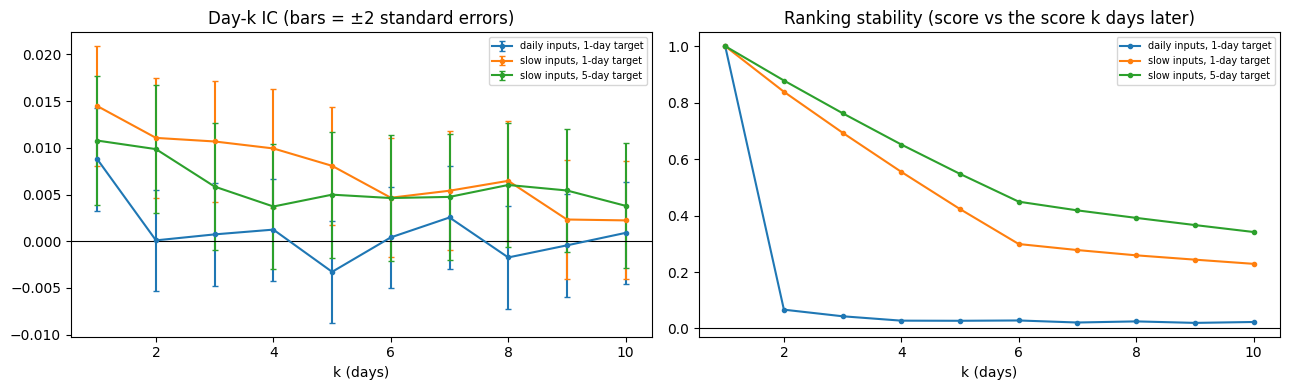

   daily inputs, 1-day target                            slow inputs, 1-day target                            slow inputs, 5-day target                           
                     day-k IC day-k SE ranking stability                  day-k IC day-k SE ranking stability                  day-k IC day-k SE ranking stability
1                      0.0088   0.0028            1.0000                    0.0145   0.0032            1.0000                    0.0108   0.0035            1.0000
2                      0.0001   0.0027            0.0667                    0.0111   0.0032            0.8385                    0.0099   0.0034            0.8783
3                      0.0007   0.0028            0.0433                    0.0107   0.0032            0.6934                    0.0058   0.0034            0.7625
5                     -0.0033   0.0027            0.0273                    0.0081   0.0032            0.4229                    0.0050   0.0034            0.5475
10                    

In [7]:
dec = {name: pc.decay(D, s, None, pc.TUNE_END) for name, s in score.items()}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, d in dec.items():
    axes[0].errorbar(d.index, d["day-k IC"], yerr=2 * d["day-k SE"], marker="o", ms=3, capsize=2, label=name)
    axes[1].plot(d.index, d["ranking stability"], marker="o", ms=3, label=name)
axes[0].set_title("Day-k IC (bars = ±2 standard errors)"); axes[1].set_title("Ranking stability (score vs the score k days later)")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("k (days)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(pd.concat({n: d.loc[[1, 2, 3, 5, 10]] for n, d in dec.items()}, axis=1).round(4).to_string())

## 5. What do the slow models use?

Share of arrows by input type (averaged over all quarters, at the chosen λ). `w` = past-week average, `m` = past-month average.

In [8]:
for name in ["slow inputs, 1-day target", "slow inputs, 5-day target"]:
    kinds = []
    for q in res[name]:
        Wk = q["W"][:, :, K[name]]
        _, j = np.nonzero(Wk)
        kinds += [q["cols"][jj].split("|")[1] if "|" in q["cols"][jj] else "?" for jj in j]
    share = pd.Series(kinds).value_counts(normalize=True).round(3)
    share.index = [("ETF " if k in ("w", "m") else "") + k for k in share.index]
    print(f"{name}:", share.to_dict())

slow inputs, 1-day target: {'ret_w': 0.279, 'sent_w': 0.188, 'attn_w': 0.169, 'ret_m': 0.144, 'sent_m': 0.102, 'attn_m': 0.083, 'ETF w': 0.024, 'ETF m': 0.012}
slow inputs, 5-day target: {'ret_w': 0.208, 'sent_w': 0.191, 'attn_w': 0.183, 'ret_m': 0.149, 'sent_m': 0.133, 'attn_m': 0.108, 'ETF w': 0.016, 'ETF m': 0.011}


## 6. Save results

In [9]:
RESULTS.mkdir(parents=True, exist_ok=True)
pd.concat(tables, names=["period", "model"]).to_csv(RESULTS / "pit_slow_inputs_results.csv")
pd.concat(dec, names=["model", "k"]).to_csv(RESULTS / "pit_slow_inputs_decay.csv")
print("Saved to", RESULTS)

Saved to /Users/max_lovinger/Documents/Thesis/CoreFragment/data/results
